# Multivariate Time-Series Change Detection

PCA, cPCA and sequential DSSI analysis of six FRED macroeconomic series.


## 1. Data preparation

INDPRO, RSAFS, PCE, UNRATE, CPIAUCSL and DGS10, aligned to monthly observations. Log differences for INDPRO, RSAFS and PCE; first differences for UNRATE and DGS10; second log differences for CPIAUCSL.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from statsmodels.tsa.stattools import adfuller

tickers = ['INDPRO', 'CPIAUCSL', 'UNRATE', 'DGS10', 'RSAFS', 'PCE']
dfs = []
for ticker in tickers:
    tmp = pd.read_csv(f'{ticker}.csv', index_col=0, parse_dates=True)
    tmp.columns = [ticker]
    dfs.append(tmp)

df = pd.concat(dfs, axis=1, sort=False)
df_monthly = df.resample('MS').mean()


levels = ['INDPRO', 'CPIAUCSL', 'RSAFS', 'PCE']
df_levels = np.log(df_monthly[levels]).diff()
rates = ['UNRATE', 'DGS10']
df_rates = df_monthly[rates].diff()
df_clean = pd.concat([df_levels, df_rates], axis=1).dropna()

def adf_test(df):
    adf_results = {}
    for col in df.columns:
        p_val = adfuller(df[col])[1]
        adf_results[col] = p_val
    return pd.Series(adf_results)

print("=== Initial ADF test results ===")
print(adf_test(df_clean))

# CPIAUCSL: apply a second log difference after the first difference fails the ADF test.
df_clean['CPIAUCSL'] = df_clean['CPIAUCSL'].diff()
df_clean = df_clean.dropna()

print("\n=== ADF results after second-differencing log CPIAUCSL ===")
print(adf_test(df_clean))

=== Initial ADF test results ===
INDPRO      7.856679e-22
CPIAUCSL    1.833723e-01
RSAFS       3.697984e-04
PCE         1.139747e-22
UNRATE      6.999145e-20
DGS10       1.574297e-14
dtype: float64

=== ADF results after second-differencing log CPIAUCSL ===
INDPRO      9.250580e-22
CPIAUCSL    4.981255e-11
RSAFS       3.873908e-04
PCE         1.347988e-22
UNRATE      8.247566e-20
DGS10       1.756255e-14
dtype: float64


## 2. PCA and cPCA before and after 2020

Background: before January 2020. Target: January 2020 onward. Fit scaling on the background. Set cPCA alpha to the target/background covariance trace ratio.


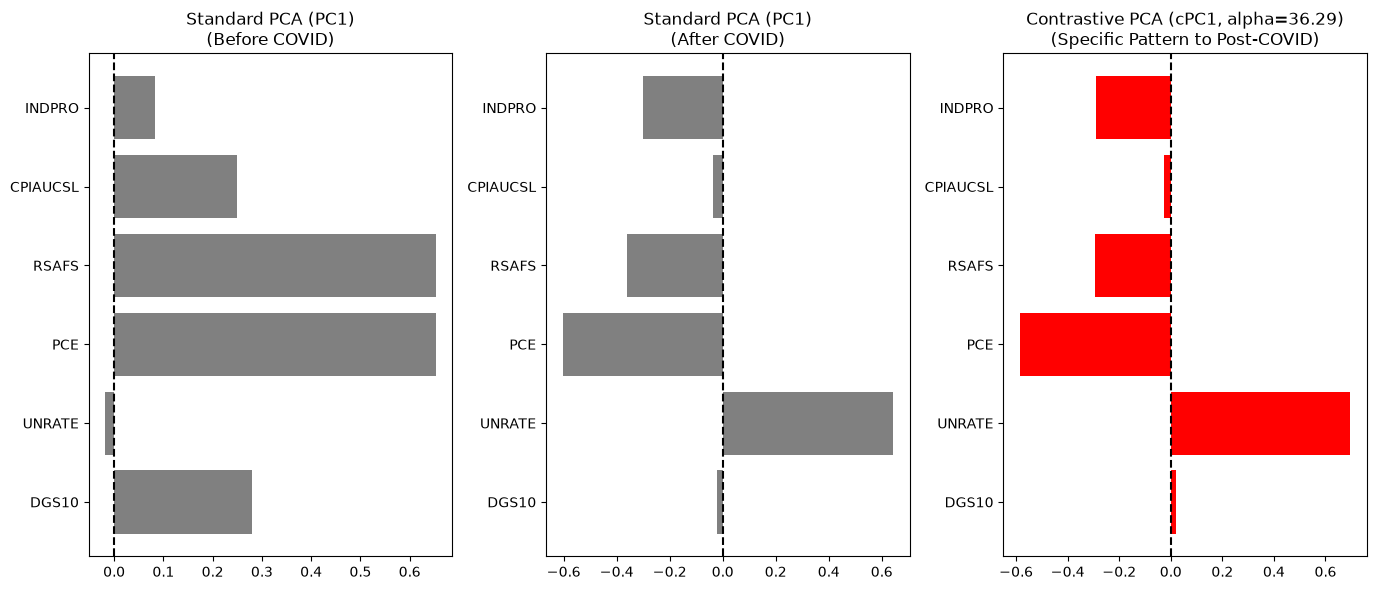

cPCA alpha = 36.29
          Std_PCA before COVID  Std_PCA after COVID  cPCA (alpha=36.29)
Feature                                                                
INDPRO                  0.0826              -0.3016             -0.2894
CPIAUCSL                0.2493              -0.0363             -0.0275
RSAFS                   0.6524              -0.3593             -0.2952
PCE                     0.6530              -0.6041             -0.5853
UNRATE                 -0.0180               0.6428              0.6967
DGS10                   0.2804              -0.0211              0.0210


In [2]:
split_date = '2020-01-01'
X_bg = df_clean[df_clean.index < split_date]
X_tg = df_clean[df_clean.index >= split_date]

scaler = StandardScaler()
scaler.fit(X_bg)
X_bg_scaled = scaler.transform(X_bg)
X_tg_scaled = scaler.transform(X_tg)

def checked_covariance(values):
    """Raise ValueError for nonfinite input or nonpositive total variance."""
    values = np.asarray(values, dtype=float)
    if values.ndim != 2 or values.shape[0] < 2 or values.shape[1] < 2:
        raise ValueError("Covariance requires at least two rows and two features")
    if not np.isfinite(values).all():
        raise ValueError("Covariance input must be finite")
    covariance = np.cov(values, rowvar=False)
    total_variance = np.trace(covariance)
    if not np.isfinite(covariance).all() or not np.isfinite(total_variance) or total_variance <= 0:
        raise ValueError("Covariance must have finite positive total variance")
    return covariance


def run_cpca(background, target):
    """Set alpha to the target/background covariance trace ratio."""
    cov_tg = checked_covariance(target)
    cov_bg = checked_covariance(background)
    if cov_tg.shape != cov_bg.shape:
        raise ValueError("Background and target must have matching features")
    alpha = np.trace(cov_tg) / np.trace(cov_bg)
    cov_fin = cov_tg - alpha * cov_bg
    vals, vecs = np.linalg.eigh(cov_fin)
    idx = np.argsort(vals)[::-1]
    return vecs[:, idx], vals[idx], alpha

cpca_vecs, cpca_vals, alpha = run_cpca(X_bg_scaled, X_tg_scaled)

pca = PCA(n_components=1)
pca.fit(X_bg_scaled)
pca_vecs1 = pca.components_.T

pca = PCA(n_components=1)
pca.fit(X_tg_scaled)
pca_vecs2 = pca.components_.T

features = df_clean.columns
fig, ax = plt.subplots(1, 3, figsize=(14, 6))

ax[0].barh(features, pca_vecs1[:, 0], color='gray')
ax[0].set_title("Standard PCA (PC1)\n(Before COVID)")
ax[0].axvline(0, color='k', linestyle='--')

ax[1].barh(features, pca_vecs2[:, 0], color='gray')
ax[1].set_title("Standard PCA (PC1)\n(After COVID)")
ax[1].axvline(0, color='k', linestyle='--')

ax[2].barh(features, cpca_vecs[:, 0], color='red')
ax[2].set_title(f"Contrastive PCA (cPC1, alpha={alpha:.2f})\n(Specific Pattern to Post-COVID)")
ax[2].axvline(0, color='k', linestyle='--')

for a in ax:
    a.invert_yaxis()

plt.tight_layout()
plt.show()

results_df = pd.DataFrame({
    'Feature': features,
    'Std_PCA before COVID': np.round(pca_vecs1[:, 0], 4),
    'Std_PCA after COVID': np.round(pca_vecs2[:, 0], 4),
    f'cPCA (alpha={alpha:.2f})': np.round(cpca_vecs[:, 0], 4)
}).set_index('Feature')

print(f"cPCA alpha = {alpha:.2f}")
print(results_df)

### Result

The saved run gives alpha ≈ 36.29: total standardized variance is higher in the target window.


## 3. Projection scores and rolling similarity

Project onto the fixed cPC1 direction and compare pre-2020 PC1 with rolling 12-month PC1 using absolute cosine similarity.


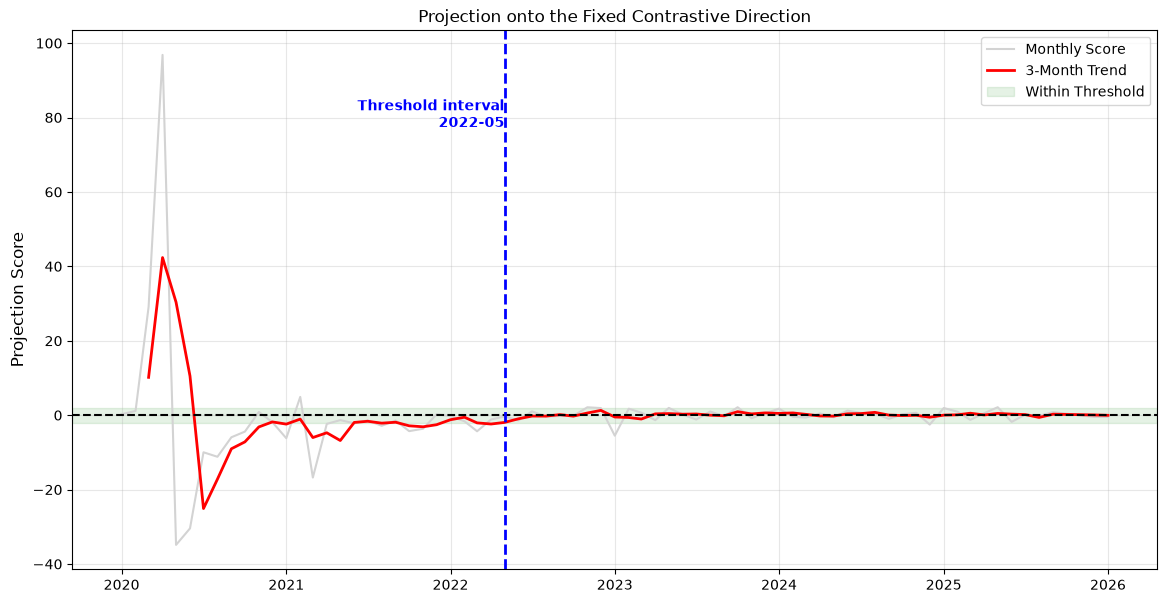

Projection threshold boundary: 2022-05


In [3]:
scores = X_tg_scaled @ cpca_vecs
proj_tg = pd.Series(scores[:, 0], index=X_tg.index)
proj_tg_roll = proj_tg.rolling(window=3).mean()
threshold = 2

def trailing_threshold_start(series, threshold):
    """Start of the trailing finite in-range interval, or None."""
    start = None
    for date, value in reversed(list(series.items())):
        if not np.isfinite(value) or abs(value) > threshold:
            break
        start = date
    return start


recovery_date = trailing_threshold_start(proj_tg_roll, threshold)
print("Projection threshold boundary: " +
      (recovery_date.strftime('%Y-%m') if recovery_date is not None else "No trailing in-range interval"))

plt.figure(figsize=(14, 7))
plt.plot(proj_tg.index, proj_tg, color='lightgray', label='Monthly Score')
plt.plot(proj_tg_roll.index, proj_tg_roll, color='red', linewidth=2, label='3-Month Trend')
plt.axhspan(-threshold, threshold, color='green', alpha=0.1, label='Within Threshold')
plt.axhline(0, color='black', linestyle='--')

if recovery_date is not None:
    plt.axvline(recovery_date, color='blue', linestyle='--', linewidth=2)
    plt.text(recovery_date, max(proj_tg) * 0.8,
             f' Threshold interval\n {recovery_date.strftime("%Y-%m")}',
             color='blue', fontweight='bold', ha='right')

plt.title('Projection onto the Fixed Contrastive Direction')
plt.ylabel('Projection Score', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

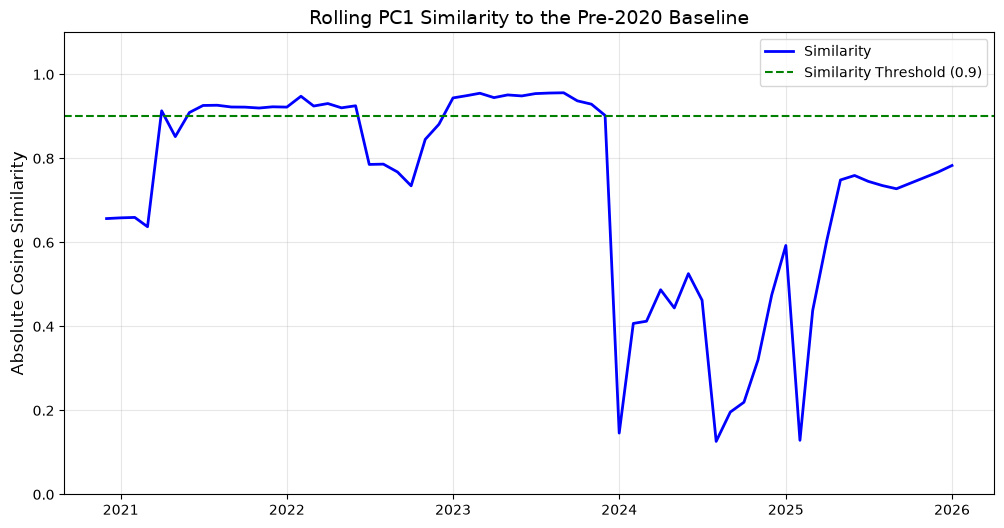

First window with PC1 similarity >= 0.9: 2021-04


In [4]:
window_size = 12
similarities = []
dates = []

for i in range(len(X_tg_scaled) - window_size + 1):
    pca = PCA(n_components=1)
    pca.fit(X_tg_scaled[i:i + window_size])
    pca_vecs_curr = pca.components_[0]
    similarity = abs(np.dot(pca_vecs1.flatten(), pca_vecs_curr))
    similarities.append(similarity)
    dates.append(X_tg.index[i + window_size - 1])

plt.figure(figsize=(12, 6))
plt.plot(dates, similarities, color='blue', linewidth=2, label='Similarity')
plt.axhline(0.9, color='green', linestyle='--', label='Similarity Threshold (0.9)')
plt.title('Rolling PC1 Similarity to the Pre-2020 Baseline', fontsize=14)
plt.ylabel('Absolute Cosine Similarity', fontsize=12)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

def first_similarity_crossing(series, threshold=0.9):
    """First finite observation reaching the threshold, or None."""
    for date, value in series.items():
        if np.isfinite(value) and value >= threshold:
            return date
    return None


sim_series = pd.Series(similarities, index=dates, dtype=float)
recovered_date = first_similarity_crossing(sim_series)
print("First window with PC1 similarity >= 0.9: " +
      (recovered_date.strftime('%Y-%m') if recovered_date is not None else "No crossing observed"))


## 4. November 2023–September 2024 comparison

Compare cPCA loadings and PC1 similarity with the pre-2020 baseline.


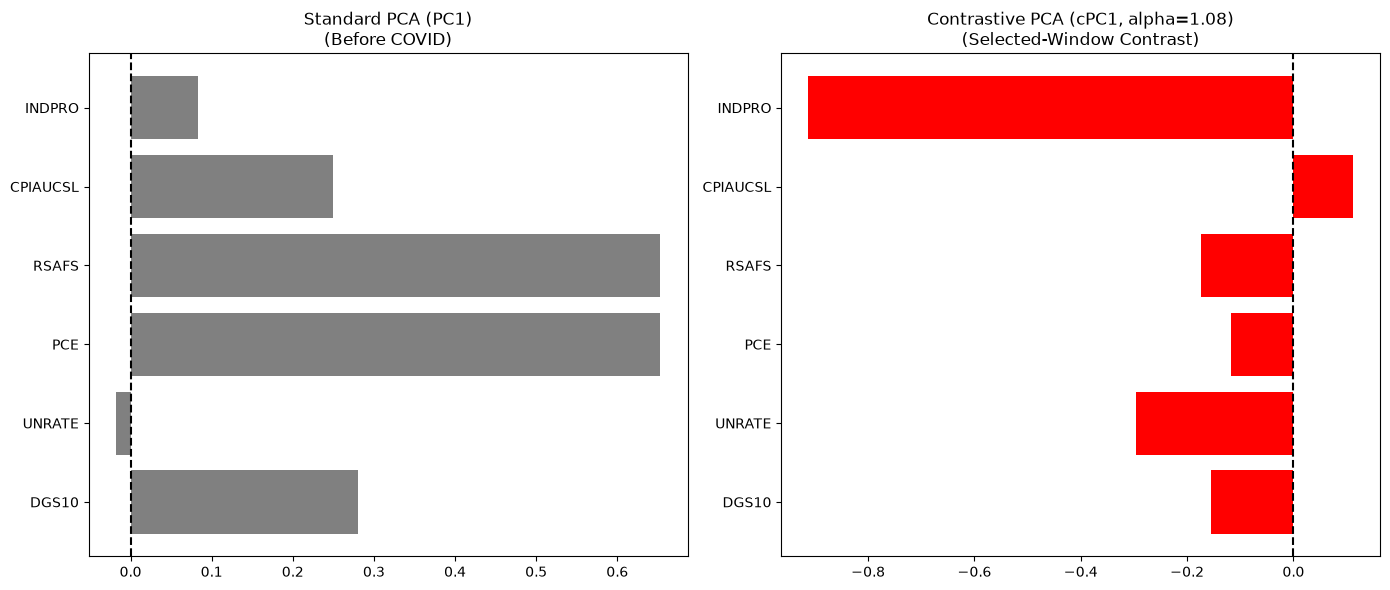

Selected-window cPCA alpha = 1.08
          Std_PCA before COVID  Selected-window cPCA (alpha=1.08)
Feature                                                          
INDPRO                  0.0826                            -0.9122
CPIAUCSL                0.2493                             0.1117
RSAFS                   0.6524                            -0.1737
PCE                     0.6530                            -0.1178
UNRATE                 -0.0180                            -0.2954
DGS10                   0.2804                            -0.1553


In [5]:
X_ai = df_clean[(df_clean.index > '2023-10-01') & (df_clean.index < '2024-10-01')]
X_ai_scaled = scaler.transform(X_ai)
cpca_ai_vecs, cpca_ai_vals, alpha_ai = run_cpca(X_bg_scaled, X_ai_scaled)

features = df_clean.columns
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].barh(features, pca_vecs1[:, 0], color='gray')
ax[0].set_title("Standard PCA (PC1)\n(Before COVID)")
ax[0].axvline(0, color='k', linestyle='--')

ax[1].barh(features, cpca_ai_vecs[:, 0], color='red')
ax[1].set_title(f"Contrastive PCA (cPC1, alpha={alpha_ai:.2f})\n(Selected-Window Contrast)")
ax[1].axvline(0, color='k', linestyle='--')

for a in ax:
    a.invert_yaxis()

plt.tight_layout()
plt.show()

results_ai = pd.DataFrame({
    'Feature': features,
    'Std_PCA before COVID': np.round(pca_vecs1[:, 0], 4),
    f'Selected-window cPCA (alpha={alpha_ai:.2f})': np.round(cpca_ai_vecs[:, 0], 4)
}).set_index('Feature')

print(f"Selected-window cPCA alpha = {alpha_ai:.2f}")
print(results_ai)

## 5. Sequential DSSI detection

`DSSI = (1 + ln(max(alpha, 1 / alpha))) * (1 - abs(cosine_similarity))`

Alpha: target/background covariance trace ratio. Expanding background, 12-month target windows.

- NORMAL: confirm a change after two consecutive DSSI crossings above 1.0.
- CRISIS: freeze the contrastive direction and track mean absolute projection.
- RECOVERY: return to NORMAL after three projections below 1.5; reset the background endpoint.


In [6]:
def detect_regime_shift(df, initial_bg_size=60, target_size=12, threshold_change=1.0, threshold_recovery=0.8):
    """Compare transformed monthly observations.
    
    initial_bg_size and target_size are in months. threshold_change applies
    to DSSI; threshold_recovery applies to mean absolute projection.
    Return events with type, date and score columns."""
    if initial_bg_size < 2 or target_size < 2:
        raise ValueError("Background and target windows require at least two observations")
    if len(df) < initial_bg_size + target_size:
        print('Lack of data')
        return pd.DataFrame()

    events = []
    bg_start_idx = 0
    bg_end_idx = initial_bg_size
    current_idx = bg_end_idx
    state = 'NORMAL'
    shock_vec = None
    change_counter = 0
    recovery_counter = 0

    while current_idx + target_size <= len(df):
        X_bg_raw = df.iloc[bg_start_idx:bg_end_idx]
        X_tg_raw = df.iloc[current_idx:current_idx + target_size]
        curr_date = X_tg_raw.index[-1]

        scaler = StandardScaler()
        X_bg = scaler.fit_transform(X_bg_raw)
        X_tg = scaler.transform(X_tg_raw)

        if state == 'NORMAL':
            cov_bg = checked_covariance(X_bg)
            cov_tg = checked_covariance(X_tg)

            alpha = np.trace(cov_tg) / np.trace(cov_bg)
            pca_bg = PCA(n_components=1).fit(X_bg)
            pca_tg = PCA(n_components=1).fit(X_tg)
            similarity = np.abs(np.dot(pca_bg.components_[0], pca_tg.components_[0]))
            dissimilarity = 1 - np.clip(similarity, 0.0, 1.0)
            alpha_weight = 1 + np.log(max(alpha, 1 / alpha) + 1e-9)
            dssi = alpha_weight * dissimilarity

            if dssi > threshold_change:
                change_counter += 1
            else:
                change_counter = 0

            if change_counter >= 2:
                print(f'[Change confirmed] {curr_date.strftime("%Y-%m")} | DSSI: {dssi:.2f} (Alpha:{alpha:.1f}, Sim:{similarity:.2f})')
                state = 'CRISIS'
                events.append({"type": "SHOCK_START", "date": curr_date, "score": dssi})

                diff_cov = cov_tg - (alpha * cov_bg)
                vals, vecs = np.linalg.eigh(diff_cov)
                shock_vec = vecs[:, -1]
                change_counter = 0

            if state == 'NORMAL':
                bg_end_idx += 1
                current_idx += 1
            else:
                current_idx += 1

        elif state == 'CRISIS':
            projection = np.mean(np.abs(X_tg @ shock_vec))

            if projection < threshold_recovery:
                recovery_counter += 1
            else:
                recovery_counter = 0

            if recovery_counter >= 3:
                print(f'[Tracking exit confirmed] {curr_date.strftime("%Y-%m")} | Residual Shock: {projection:.2f}')
                state = 'NORMAL'
                events.append({"type": "RECOVERY", "date": curr_date, "score": projection})

                bg_end_idx = current_idx
                recovery_counter = 0

            current_idx += 1

    return pd.DataFrame(events)


events_df = detect_regime_shift(df_clean, initial_bg_size=60, target_size=12, threshold_change=1, threshold_recovery=1.5)
print(events_df)

[Change confirmed] 2020-05 | DSSI: 2.03 (Alpha:173.5, Sim:0.67)
[Tracking exit confirmed] 2022-11 | Residual Shock: 1.03
[Change confirmed] 2023-12 | DSSI: 1.46 (Alpha:0.5, Sim:0.12)
[Tracking exit confirmed] 2024-03 | Residual Shock: 1.01
[Change confirmed] 2024-05 | DSSI: 1.76 (Alpha:0.4, Sim:0.09)
[Tracking exit confirmed] 2024-08 | Residual Shock: 1.10
[Change confirmed] 2024-10 | DSSI: 1.67 (Alpha:0.4, Sim:0.15)
[Tracking exit confirmed] 2025-01 | Residual Shock: 0.92
[Change confirmed] 2025-03 | DSSI: 1.93 (Alpha:0.3, Sim:0.08)
[Tracking exit confirmed] 2025-06 | Residual Shock: 0.84
[Change confirmed] 2025-08 | DSSI: 2.42 (Alpha:0.2, Sim:0.03)
[Tracking exit confirmed] 2026-01 | Residual Shock: 0.53
           type       date     score
0   SHOCK_START 2020-05-01  2.025544
1      RECOVERY 2022-11-01  1.026288
2   SHOCK_START 2023-12-01  1.461085
3      RECOVERY 2024-03-01  1.006866
4   SHOCK_START 2024-05-01  1.760898
5      RECOVERY 2024-08-01  1.099839
6   SHOCK_START 2024-10-0